## 06 · EMT-transcription-factor expression

Overlay the most informative EMT-TFs for this dataset on the manifold. The canonical Snail/Zeb/Twist factors are barely expressed in cutaneous SCC (an epithelial tumour where classical EMT is rare), so the panel is chosen by **detectable expression** and **arm specificity**: **SNAI2** (SLUG) marks the pSom/Differentiated arm, **SOX9** marks the Gast/basal hub end. Expression is read from the un-regressed log-normalised matrix (the processed h5ad stores the cell-cycle-regressed values used for the embedding).

In [1]:
import os, sys, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
# import the 3CA loader to fetch un-regressed expression
pth_ccca = os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..'))
sys.path.append(pth_ccca)
from scripts.load import load_CCCA_adata

name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
dset = re.sub(r'-\d+$', '', name)
pth      = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_raw  = os.path.join(pth_data, 'unzip', 'CCCA', f'Data_{dset}')
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [3]:
# load processed data (embedding + subtypes)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

Out[3]: 
AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'


AnnData object with n_obs × n_vars = 10518 × 21042
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'S_score', 'G2M_score', 'phase', 'leiden', '_Basal', '_Differentiated', '_TSK'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [4]:
# load un-regressed log-normalised expression, aligned to the processed cells
raw = load_CCCA_adata(pth_raw)
raw = raw[adata.obs_names].copy()
raw.obsm['X_umap'] = adata.obsm['X_umap']
raw.obs['celltype'] = adata.obs['celltype'].values

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.


saved ../../../../../../figures/cancer/vertebrate/CCCA/Claude/Skin/Ji2020_Skin-7/expression.pdf


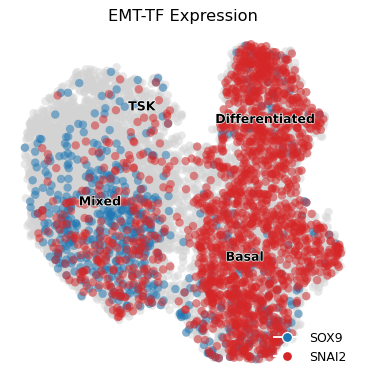

In [5]:
# EMT-TF panel for this dataset: (colour, display threshold).
# SNAI2 -> pSom/Differentiated arm ; SOX9 -> Gast/basal hub end.
g_plt = {'SOX9'  : ('tab:blue', 0.6),
         'SNAI2' : ('tab:red', 0.9)}

# save EMT-TF expression figure (categorical overlay of thresholded expressers)
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(raw, size = 180, alpha = .5, frameon = False, show = False, ax = ax)
for var, (c, thresh) in g_plt.items():
    sub = raw[np.asarray(raw[:, var].X.todense()).ravel() > thresh].copy()
    sc.pl.umap(sub, na_color = c, size = 180, alpha = .5,
               frameon = False, show = False, ax = ax)
sc.pl.umap(raw, color = 'celltype', size = 180, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
           markersize=8, label=v) for v,(c,_) in g_plt.items()]
ax.legend(handles=handles, frameon=False, loc='lower right')
ax.set_title('EMT-TF Expression', size = 13)
fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight'); print('saved', fn)